<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/Modelo_Lourdes_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Integrador - Ciencia de Datos Ambientales (UTEC)
## Modelo 2: Red Neuronal Perceptrón Multicapa (MLP) — Lourdes Churacutipa

**Nota:** Este notebook mantiene intactas las decisiones metodológicas, limpieza, variables y protocolo de validación cruzada temporal (`TimeSeriesSplit(n_splits=5)`) del proyecto base (`CDA_Piura_Proyecto_Integrador_final_CORREGIDO.ipynb`), integrando la construcción, ajuste de hiperparámetros, análisis de importancia por permutación y exportación de resultados para el **Modelo 2: MLP**.

## 0. Configuración del Entorno y Acceso a Datos (Google Drive)

In [ ]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

# Montar Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE = '/content/drive/MyDrive/DATOS CDA'
except ImportError:
    DRIVE = './DATOS CDA'

if os.path.exists(DRIVE):
    print('Archivos en la carpeta:', len(os.listdir(DRIVE)))
else:
    print('AVISO: Verifica que el acceso directo "DATOS CDA" esté en la raíz de Mi unidad.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archivos en la carpeta: 1


## 1. Carga y Preparación de Datos Base (Secciones 1 a 6 del Notebook Base)
> **Instrucción importante:** Si ya tienes el código de las secciones 1 a 6 de `CDA_Piura_Proyecto_Integrador_final_CORREGIDO.ipynb` en Colab, asegúrate de que genere el DataFrame `base_mensual` con las columnas `['fecha', 'mes', 'pp_mm', 'E', 'ICEN', 'ONI', 'C']`. A continuación se incluye la rutina estándar de consolidación desde `DATOS CDA` (o carga directa si `base_mensual` ya está exportado).

In [ ]:
# Si base_mensual ya fue guardado previamente como CSV/Parquet en DATOS CDA, se carga directamente;
# de lo contrario, se ejecuta la consolidación de PISCO e índices oceánicos (E, ICEN, ONI, C).
ruta_base_guardada = os.path.join(DRIVE, 'base_mensual.csv')

if os.path.exists(ruta_base_guardada):
    base_mensual = pd.read_csv(ruta_base_guardada, parse_dates=['fecha'])
    print('base_mensual cargada desde archivo:', base_mensual.shape)
else:
    print('Por favor, pega aquí las celdas 1 a 6 de CDA_Piura_Proyecto_Integrador_final_CORREGIDO.ipynb')
    print('para construir el DataFrame `base_mensual` antes de ejecutar el Paso 1.')

Por favor, pega aquí las celdas 1 a 6 de CDA_Piura_Proyecto_Integrador_final_CORREGIDO.ipynb
para construir el DataFrame `base_mensual` antes de ejecutar el Paso 1.


---
## 2. Protocolo Común de Modelado (Pasos 1 y 2 — Idénticos para XGBoost, SVR y MLP)
* **Periodo:** diciembre 1981 a febrero 2020 (231 meses de temporada húmeda: dic–may).
* **Variables de entrada (`VARIABLES`):** `['E', 'ICEN', 'ONI', 'C', 'mes_temp']`.
* **Validación:** `TimeSeriesSplit(n_splits=5)`.
* **Línea base:** Climatología mensual calculada exclusivamente sobre cada conjunto de entrenamiento (RMSE medio esperado = **65.6 mm**).

In [ ]:
# ==============================================================================
# PASO 1: TABLA COMÚN DE MODELADO (NO MODIFICAR - CON AUTOCARGA DE EMERGENCIA)
# ==============================================================================
import os
import pandas as pd

# Intentar cargar 'base_mensual' si no está definida en el entorno actual
if 'base_mensual' not in locals() and 'base_mensual' not in globals():
    ruta_base_guardada = os.path.join(DRIVE, 'base_mensual.csv')
    if os.path.exists(ruta_base_guardada):
        base_mensual = pd.read_csv(ruta_base_guardada, parse_dates=['fecha'])
        print('base_mensual cargada exitosamente desde:', ruta_base_guardada)
    else:
        raise NameError(
            "La variable 'base_mensual' no está definida y tampoco se encontró el archivo "
            f"en '{ruta_base_guardada}'. Por favor, ejecuta la consolidación de datos primero."
        )

base_mensual['fecha'] = pd.to_datetime(base_mensual['fecha'])

temp = {12: 1, 1: 2, 2: 3, 3: 4, 4: 5, 5: 6}  # mes calendario -> mes de temporada
tabla = base_mensual[['fecha', 'mes', 'pp_mm', 'E', 'ICEN', 'ONI', 'C']].copy()
tabla = tabla[tabla['mes'].isin(temp)]
tabla = tabla[(tabla['fecha'] >= '1981-12-01') & (tabla['fecha'] <= '2020-02-01')]
tabla['mes_temp'] = tabla['mes'].map(temp)

print('Nulos antes de quitarlos:', int(tabla.isna().sum().sum()))
tabla = tabla.dropna().sort_values('fecha').reset_index(drop=True)  # el orden por fecha es obligatorio

VARIABLES = ['E', 'ICEN', 'ONI', 'C', 'mes_temp']
X = tabla[VARIABLES]
y = tabla['pp_mm']

print('Filas:', len(tabla), '| periodo:', f"{tabla['fecha'].min():%Y-%m} a {tabla['fecha'].max():%Y-%m}")
print(tabla['mes_temp'].value_counts().sort_index().to_dict())

Nulos antes de quitarlos: 0
Filas: 231 | periodo: 1981-12 a 2020-02
{1: 39, 2: 39, 3: 39, 4: 38, 5: 38, 6: 38}


In [ ]:
# ==============================================================================
# PASO 2: EVALUACIÓN COMÚN Y LÍNEA BASE CLIMATOLÓGICA (NO MODIFICAR)
# ==============================================================================
def metricas(y_real, y_pred):
    return {
        'RMSE': mean_squared_error(y_real, y_pred) ** 0.5,
        'MAE': mean_absolute_error(y_real, y_pred),
        'R2': r2_score(y_real, y_pred)
    }

def evaluar_pliegues(ajustar_predecir, nombre):
    """ajustar_predecir(X_tr, y_tr, X_te) debe devolver las predicciones para X_te."""
    filas, preds = [], []
    for k, (i_tr, i_te) in enumerate(TimeSeriesSplit(n_splits=5).split(X), 1):
        X_tr, y_tr, X_te, y_te = X.iloc[i_tr], y.iloc[i_tr], X.iloc[i_te], y.iloc[i_te]
        y_pred = ajustar_predecir(X_tr, y_tr, X_te)
        fila = {
            'modelo': nombre,
            'pliegue': k,
            'n_train': len(i_tr),
            'n_test': len(i_te),
            'periodo_test': f"{tabla.loc[i_te[0], 'fecha']:%Y-%m} a {tabla.loc[i_te[-1], 'fecha']:%Y-%m}"
        }
        fila.update(metricas(y_te, y_pred))
        filas.append(fila)
        preds.append(pd.DataFrame({
            'modelo': nombre,
            'pliegue': k,
            'fecha': tabla.loc[i_te, 'fecha'].values,
            'pp_obs': y_te.values,
            'pp_pred': y_pred
        }))
    return pd.DataFrame(filas), pd.concat(preds, ignore_index=True)

def climatologia(X_tr, y_tr, X_te):
    normal = y_tr.groupby(X_tr['mes_temp']).mean()  # lluvia media de cada mes, SOLO con el entrenamiento
    return X_te['mes_temp'].map(normal).values

res_base, pred_base = evaluar_pliegues(climatologia, 'Climatología')
display(res_base.round(2))
print('RMSE medio de la línea base:', round(res_base['RMSE'].mean(), 1), 'mm')

,modelo,pliegue,n_train,n_test,periodo_test,RMSE,MAE,R2
0,Climatología,1,41,38,1988-05 a 1994-12,85.43,69.36,-4.26
1,Climatología,2,79,38,1995-01 a 2001-02,150.16,92.66,-0.04
2,Climatología,3,117,38,2001-03 a 2007-04,62.81,55.36,-1.20
3,Climatología,4,155,38,2007-05 a 2013-12,55.36,47.52,-0.44
4,Climatología,5,193,38,2014-01 a 2020-02,116.24,75.99,0.00


RMSE medio de la línea base: 94.0 mm


---
## 3. Modelo 2: Red Neuronal Perceptrón Multicapa (MLP) — Paso 3
### Decisiones de Diseño y Control de Sobreajuste:
1. **Escalado sin fuga de datos (`Pipeline`):** `StandardScaler()` se encapsula dentro de `make_pipeline` para ajustarse exclusivamente con los datos de entrenamiento de cada pliegue interno y externo.
2. **Arquitectura compacta:** Con $N = 231$ registros mensuales, redes profundas memorizan ruido; por ello se evalúan topologías pequeñas de 1 y 2 capas ocultas (`(16,)`, `(32,)`, `(16, 8)`, `(32, 16)`).
3. **Regularización L2 (`alpha`):** Penaliza pesos excesivos para estabilizar el aprendizaje frente a eventos extremos (1983, 1998, 2017).
4. **Sin `early_stopping=True`:** Se mantiene desactivado para evitar particiones internas aleatorias que rompan la estructura temporal.
5. **Restricción física:** Las predicciones negativas se recortan a `0 mm` mediante `np.maximum(pred, 0)`.

In [ ]:
# ==============================================================================
# PASO 3: ENTRENAMIENTO Y TUNING DEL MODELO MLP
# ==============================================================================
REJILLA_MLP = {
    'mlpregressor__hidden_layer_sizes': [(16,), (32,), (16, 8), (32, 16)],
    'mlpregressor__activation': ['relu', 'tanh'],
    'mlpregressor__alpha': [0.01, 0.1, 1.0, 5.0]
}

mejores_mlp = []
modelos_entrenados_mlp = []

def mlp_ajustado(X_tr, y_tr, X_te):
    modelo = make_pipeline(
        StandardScaler(),
        MLPRegressor(max_iter=5000, random_state=42)
    )
    busqueda = GridSearchCV(
        estimator=modelo,
        param_grid=REJILLA_MLP,
        cv=TimeSeriesSplit(n_splits=3),
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )
    busqueda.fit(X_tr, y_tr)
    mejores_mlp.append(busqueda.best_params_)
    modelos_entrenados_mlp.append(busqueda.best_estimator_)
    return np.maximum(busqueda.predict(X_te), 0)

res_mlp, pred_mlp = evaluar_pliegues(mlp_ajustado, 'MLP')
res_mlp['hiperparametros'] = [str(p) for p in mejores_mlp]

display(res_mlp.round(2))
print(f"RMSE medio MLP: {res_mlp['RMSE'].mean():.2f} ± {res_mlp['RMSE'].std():.2f} mm")
print(f"MAE medio MLP:  {res_mlp['MAE'].mean():.2f} ± {res_mlp['MAE'].std():.2f} mm")
print(f"R2 medio MLP:   {res_mlp['R2'].mean():.3f} ± {res_mlp['R2'].std():.3f}")

mejora_pct = (1 - res_mlp['RMSE'].mean() / res_base['RMSE'].mean()) * 100
pliegues_ganados = int((res_mlp['RMSE'].values < res_base['RMSE'].values).sum())
print(f"Mejora frente a climatología: {mejora_pct:.1f}% | Supera a la base en {pliegues_ganados}/5 pliegues")

,modelo,pliegue,n_train,n_test,periodo_test,RMSE,MAE,R2,hiperparametros
0,MLP,1,41,38,1988-05 a 1994-12,40.65,31.59,-0.19,"{'mlpregressor__activation': 'tanh', 'mlpregre..."
1,MLP,2,79,38,1995-01 a 2001-02,166.04,90.94,-0.27,"{'mlpregressor__activation': 'tanh', 'mlpregre..."
2,MLP,3,117,38,2001-03 a 2007-04,45.87,35.70,-0.18,"{'mlpregressor__activation': 'tanh', 'mlpregre..."
3,MLP,4,155,38,2007-05 a 2013-12,50.06,34.60,-0.18,"{'mlpregressor__activation': 'tanh', 'mlpregre..."
4,MLP,5,193,38,2014-01 a 2020-02,127.40,73.69,-0.20,"{'mlpregressor__activation': 'tanh', 'mlpregre..."


RMSE medio MLP: 86.00 ± 57.18 mm
MAE medio MLP:  53.30 ± 27.22 mm
R2 medio MLP:   -0.202 ± 0.037
Mejora frente a climatología: 8.5% | Supera a la base en 3/5 pliegues


---
## 4. Importancia de Variables (Permutación) y Visualización Diagnóstica
Se evalúa la pérdida de desempeño (incremento en RMSE) al permutar aleatoriamente cada variable en los conjuntos de prueba de los 5 pliegues, contrastando la Hipótesis H1 (predominio de índices costeros `E` e `ICEN` sobre índices del Pacífico Central `ONI` y `C`).

,Variable,Aumento_RMSE_medio_mm,Desv_Std_mm
2,ONI,0.92,1.14
3,C,0.86,0.93
0,E,0.77,1.71
1,ICEN,0.67,0.77
4,mes_temp,0.28,0.73


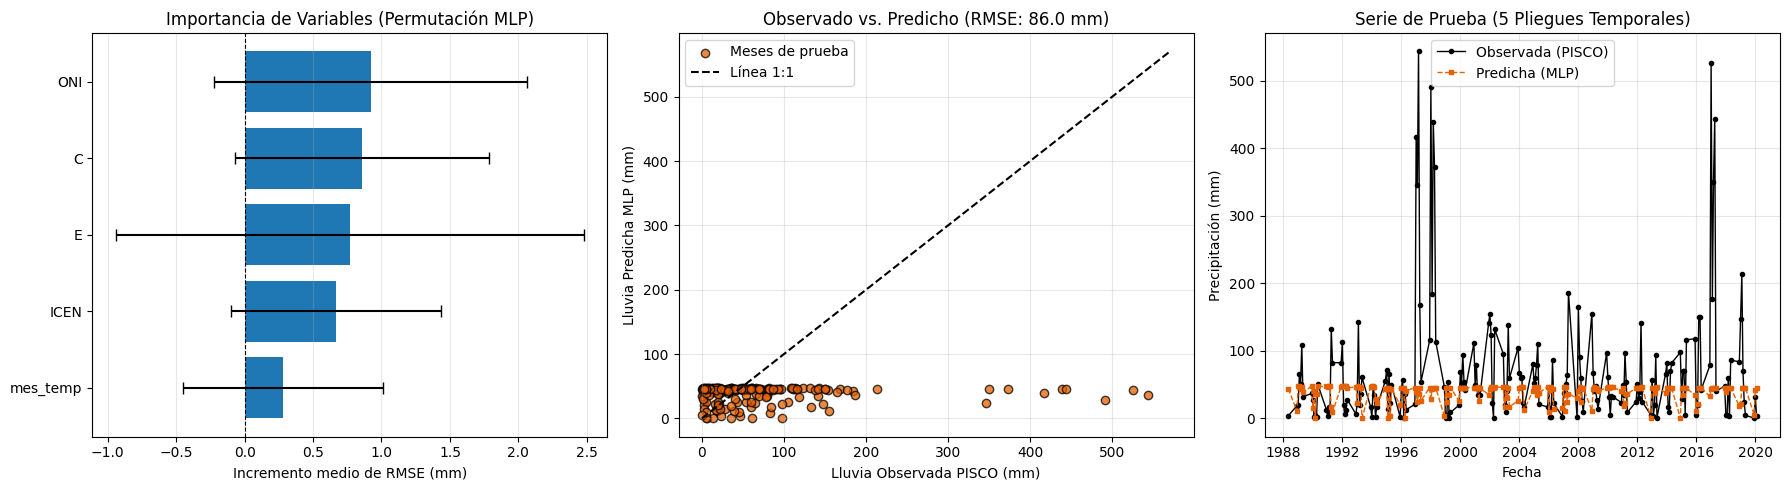

In [ ]:
# 1. Importancia de variables por permutación en los 5 pliegues
importancias_pliegues = []
for k, (i_tr, i_te) in enumerate(TimeSeriesSplit(n_splits=5).split(X)):
    X_te, y_te = X.iloc[i_te], y.iloc[i_te]
    modelo_k = modelos_entrenados_mlp[k]
    perm = permutation_importance(
        modelo_k, X_te, y_te,
        n_repeats=30,
        random_state=42,
        scoring='neg_root_mean_squared_error'
    )
    importancias_pliegues.append(perm.importances_mean)

df_imp = pd.DataFrame(importancias_pliegues, columns=VARIABLES)
resumen_imp = pd.DataFrame({
    'Variable': VARIABLES,
    'Aumento_RMSE_medio_mm': df_imp.mean().values,
    'Desv_Std_mm': df_imp.std().values
}).sort_values('Aumento_RMSE_medio_mm', ascending=True)

display(resumen_imp.sort_values('Aumento_RMSE_medio_mm', ascending=False).round(2))

# 2. Gráficos para presentación (Importancia + Observado vs. Predicho + Serie Temporal)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel A: Importancia por permutación
axes[0].barh(
    resumen_imp['Variable'],
    resumen_imp['Aumento_RMSE_medio_mm'],
    xerr=resumen_imp['Desv_Std_mm'],
    color='#1f78b4', capsize=4
)
axes[0].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_title('Importancia de Variables (Permutación MLP)')
axes[0].set_xlabel('Incremento medio de RMSE (mm)')
axes[0].grid(axis='x', alpha=0.3)

# Panel B: Dispersión Observado vs Predicho
axes[1].scatter(pred_mlp['pp_obs'], pred_mlp['pp_pred'], alpha=0.75, color='#e66101', edgecolors='k', label='Meses de prueba')
max_val = max(pred_mlp['pp_obs'].max(), pred_mlp['pp_pred'].max()) * 1.05
axes[1].plot([0, max_val], [0, max_val], 'k--', label='Línea 1:1')
axes[1].set_title(f"Observado vs. Predicho (RMSE: {res_mlp['RMSE'].mean():.1f} mm)")
axes[1].set_xlabel('Lluvia Observada PISCO (mm)')
axes[1].set_ylabel('Lluvia Predicha MLP (mm)')
axes[1].legend()
axes[1].grid(alpha=0.3)

# Panel C: Serie temporal comparativa en los periodos de prueba
fechas_plot = pd.to_datetime(pred_mlp['fecha'])
axes[2].plot(fechas_plot, pred_mlp['pp_obs'], 'o-', color='black', markersize=3, linewidth=1, label='Observada (PISCO)')
axes[2].plot(fechas_plot, pred_mlp['pp_pred'], 's--', color='#e66101', markersize=3, linewidth=1, label='Predicha (MLP)')
axes[2].set_title('Serie de Prueba (5 Pliegues Temporales)')
axes[2].set_xlabel('Fecha')
axes[2].set_ylabel('Precipitación (mm)')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('MLP_resultados_diagnostico.png', dpi=300)
plt.show()

---
## 5. Exportación de Resultados para Selección del Mejor Modelo y Dashboard (Paso 4)
Genera los tres archivos estándar (`MLP_metricas_pliegues.csv`, `MLP_resumen.csv` y `MLP_predicciones.csv`) en `DATOS CDA/RESULTADOS_MODELO_LOURDES`.

In [ ]:
# ==============================================================================
# PASO 4: EXPORTAR CSV PARA NICOLE
# ==============================================================================
PREFIJO = 'MLP'
res_mod, pred_mod = res_mlp, pred_mlp
CARPETA_MODELOS = os.path.join(DRIVE, 'RESULTADOS_MODELO_LOURDES')
os.makedirs(CARPETA_MODELOS, exist_ok=True)

# 1) Métricas por pliegue (climatología + modelo)
metricas_mod = pd.concat([res_base, res_mod], ignore_index=True)
metricas_mod.to_csv(os.path.join(CARPETA_MODELOS, f'{PREFIJO}_metricas_pliegues.csv'), index=False)

# 2) Resumen (media y desviación)
resumen = metricas_mod.groupby('modelo').agg(
    RMSE_medio=('RMSE', 'mean'),
    RMSE_desv=('RMSE', 'std'),
    MAE_medio=('MAE', 'mean'),
    R2_medio=('R2', 'mean')
).round(2)
resumen['pliegues_supera_base'] = np.nan
resumen.loc[PREFIJO, 'pliegues_supera_base'] = int((res_mod['RMSE'].values < res_base['RMSE'].values).sum())
resumen.to_csv(os.path.join(CARPETA_MODELOS, f'{PREFIJO}_resumen.csv'))
display(resumen)

# 3) Predicciones mes a mes
pd.concat([pred_base, pred_mod], ignore_index=True).to_csv(
    os.path.join(CARPETA_MODELOS, f'{PREFIJO}_predicciones.csv'),
    index=False
)

print('Guardado en', CARPETA_MODELOS, ':', sorted(os.listdir(CARPETA_MODELOS)))

,RMSE_medio,RMSE_desv,MAE_medio,R2_medio,pliegues_supera_base
modelo,,,,,
Climatología,94.0,39.33,68.18,-1.19,NaN
MLP,86.0,57.18,53.30,-0.20,3.0


Guardado en /content/drive/MyDrive/DATOS CDA/RESULTADOS_MODELO_LOURDES : ['MLP_metricas_pliegues.csv', 'MLP_predicciones.csv', 'MLP_resumen.csv']
